# Prix de l'immobilier à Paris et en petite couronne (2024)
### Analyse exploratoire et modèle de prédiction du prix des appartements

**Auteure :** Fatou Sarr — Master 1 MIAGE, Data, IA & Big Data

**Question métier :** combien vaut un appartement à Paris et en petite couronne, et quels facteurs expliquent son prix ?

**Données :** *Demandes de Valeurs Foncières* (DVF) 2024 publiées par la DGFiP, version géolocalisée d'Etalab. Chaque ligne décrit un bien vendu (prix, adresse, surface, nombre de pièces, coordonnées GPS).

**Démarche :**
1. Chargement des données brutes
2. Nettoyage : garder uniquement les ventes simples d'un appartement, retirer les valeurs aberrantes
3. Analyse exploratoire : distributions, comparaisons géographiques, saisonnalité
4. Modélisation : prédire le prix de vente, comparer plusieurs modèles
5. Conclusions et limites

In [1]:
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.float_format", lambda x: f"{x:,.0f}".replace(",", " "))
RANDOM_STATE = 42

## 1. Chargement des données brutes

In [2]:
fichiers = sorted(glob.glob("../data/raw/dvf_2024_*.csv.gz"))
raw = pd.concat(
    (pd.read_csv(f, dtype={"code_commune": str, "code_postal": str, "code_departement": str}, low_memory=False)
     for f in fichiers),
    ignore_index=True,
)
print(f"{len(raw):,} lignes, {raw['id_mutation'].nunique():,} mutations (ventes), {raw.shape[1]} colonnes".replace(",", " "))
raw[["id_mutation", "date_mutation", "nature_mutation", "valeur_fonciere", "nom_commune",
     "type_local", "surface_reelle_bati", "nombre_pieces_principales"]].head()

229 275 lignes  90 641 mutations (ventes)  40 colonnes


,id_mutation,date_mutation,nature_mutation,valeur_fonciere,nom_commune,type_local,surface_reelle_bati,nombre_pieces_principales
0,2024-1193218,2024-01-04,Vente,1 042 000,Paris 20e Arrondissement,Appartement,86,4
1,2024-1193218,2024-01-04,Vente,1 042 000,Paris 20e Arrondissement,Dépendance,NaN,0
2,2024-1193218,2024-01-04,Vente,1 042 000,Paris 20e Arrondissement,Dépendance,NaN,0
3,2024-1193218,2024-01-04,Vente,1 042 000,Paris 20e Arrondissement,Dépendance,NaN,0
4,2024-1193218,2024-01-04,Vente,1 042 000,Paris 20e Arrondissement,Dépendance,NaN,0


## 2. Nettoyage

Une **mutation** (une vente) peut regrouper plusieurs lignes : un appartement, une cave, un parking… et le prix (`valeur_fonciere`) est répété sur chaque ligne. Pour pouvoir calculer un prix au m² fiable, on garde uniquement :

- les **ventes** classiques (pas les échanges, adjudications, VEFA…) ;
- les mutations contenant **exactement un appartement** et aucune maison ni local commercial (les dépendances comme une cave ou un parking sont acceptées) ;
- des surfaces et prix au m² **plausibles** : on écarte les prix sous 1 500 €/m² ou au-dessus de 35 000 €/m² (ventes symboliques, erreurs de saisie), puis les 1 % les plus extrêmes de chaque côté.

In [3]:
etapes = {"Lignes brutes": len(raw)}

df = raw[raw["nature_mutation"] == "Vente"].copy()
etapes["Ventes uniquement"] = df["id_mutation"].nunique()

# Composition de chaque mutation
compo = df.groupby("id_mutation")["type_local"].agg(
    n_appart=lambda s: (s == "Appartement").sum(),
    n_autres=lambda s: s.isin(["Maison", "Local industriel. commercial ou assimilé"]).sum(),
)
ids_ok = compo.index[(compo["n_appart"] == 1) & (compo["n_autres"] == 0)]
df = df[df["id_mutation"].isin(ids_ok) & (df["type_local"] == "Appartement")]
etapes["Un seul appartement"] = len(df)

df = df.dropna(subset=["valeur_fonciere", "surface_reelle_bati", "longitude", "latitude"])
df = df[(df["surface_reelle_bati"] >= 9) & (df["nombre_pieces_principales"] >= 1)]
# Coordonnées GPS hors de Paris / petite couronne = erreurs de géolocalisation
df = df[df["latitude"].between(48.7, 49.0) & df["longitude"].between(2.1, 2.65)]
df["prix_m2"] = df["valeur_fonciere"] / df["surface_reelle_bati"]
etapes["Valeurs renseignées"] = len(df)

# Bornes absolues (ventes symboliques, erreurs de saisie), puis 1 % des valeurs extrêmes de chaque côté
df = df[df["prix_m2"].between(1500, 35000)]
bas, haut = df["prix_m2"].quantile([0.01, 0.99])
df = df[df["prix_m2"].between(bas, haut) & (df["surface_reelle_bati"] <= df["surface_reelle_bati"].quantile(0.995))]
etapes["Sans valeurs aberrantes"] = len(df)

df["date_mutation"] = pd.to_datetime(df["date_mutation"])
df["mois"] = df["date_mutation"].dt.month
df["departement"] = df["code_departement"].map({"75": "Paris", "92": "Hauts-de-Seine", "93": "Seine-Saint-Denis", "94": "Val-de-Marne"})
df["commune"] = df["nom_commune"].str.replace(" Arrondissement", "", regex=False)

print(f"Prix au m² conservés entre {bas:,.0f} € et {haut:,.0f} €".replace(",", " "))
pd.Series(etapes, name="volume").to_frame()

Prix au m² conservés entre 2 000 € et 19 017 €


,volume
Lignes brutes,229275
Ventes uniquement,81928
Un seul appartement,54171
Valeurs renseignées,53739
Sans valeurs aberrantes,51200


## 3. Analyse exploratoire

### 3.1 Distribution du prix au m²

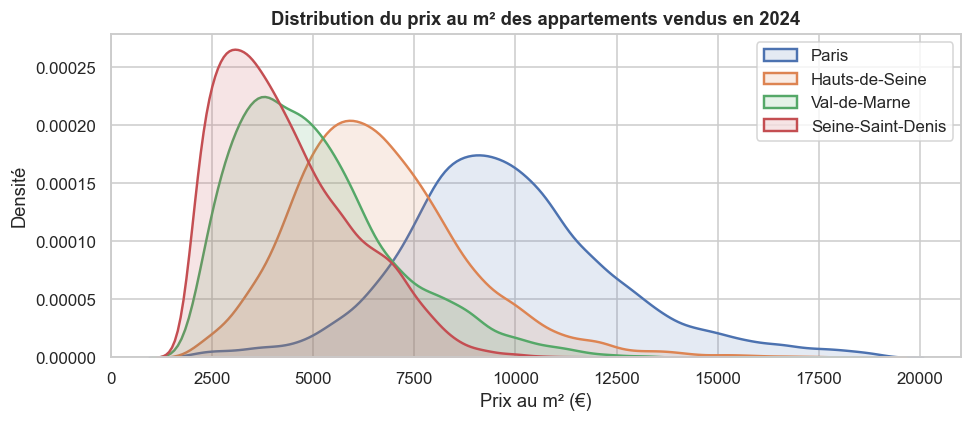

,ventes,prix_m2_median,prix_median,surface_mediane
departement,,,,
Paris,23785,9 554,379 500,41
Hauts-de-Seine,12753,6 395,320 000,55
Val-de-Marne,8192,4 697,230 000,55
Seine-Saint-Denis,6470,4 000,187 010,50


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for dep, couleur in zip(["Paris", "Hauts-de-Seine", "Val-de-Marne", "Seine-Saint-Denis"], sns.color_palette("deep")):
    sns.kdeplot(df.loc[df["departement"] == dep, "prix_m2"], ax=ax, label=dep, fill=True, alpha=.15, color=couleur, linewidth=1.6)
ax.set(title="Distribution du prix au m² des appartements vendus en 2024", xlabel="Prix au m² (€)", ylabel="Densité")
ax.legend()
plt.tight_layout(); plt.savefig("../figures/distribution_prix_m2.png", bbox_inches="tight"); plt.show()

resume = df.groupby("departement").agg(
    ventes=("prix_m2", "size"),
    prix_m2_median=("prix_m2", "median"),
    prix_median=("valeur_fonciere", "median"),
    surface_mediane=("surface_reelle_bati", "median"),
).sort_values("prix_m2_median", ascending=False)
resume

### 3.2 Paris : prix au m² médian par arrondissement

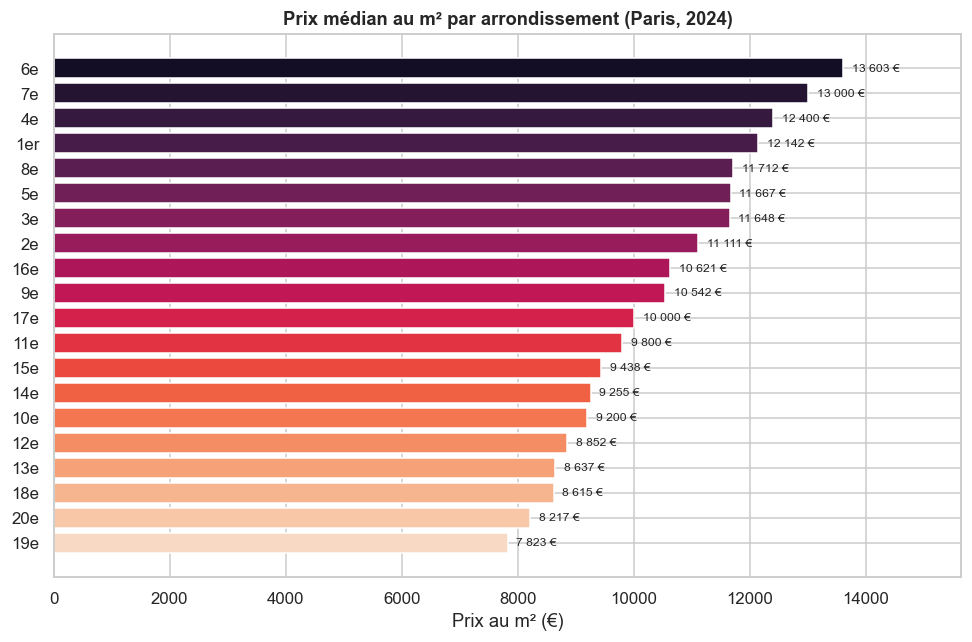

Écart entre l'arrondissement le plus cher (6e) et le moins cher (19e) : x1.74


In [5]:
paris = df[df["departement"] == "Paris"]
arr = paris.groupby("commune")["prix_m2"].median().sort_values()
arr.index = arr.index.str.replace("Paris ", "", regex=False)

fig, ax = plt.subplots(figsize=(9, 6))
couleurs = sns.color_palette("rocket_r", len(arr))
ax.barh(arr.index, arr.values, color=couleurs)
for i, v in enumerate(arr.values):
    ax.text(v + 150, i, f"{v:,.0f} €".replace(",", " "), va="center", fontsize=8)
ax.set(title="Prix médian au m² par arrondissement (Paris, 2024)", xlabel="Prix au m² (€)")
ax.set_xlim(0, arr.max() * 1.15)
plt.tight_layout(); plt.savefig("../figures/paris_arrondissements.png", bbox_inches="tight"); plt.show()

print(f"Écart entre l'arrondissement le plus cher ({arr.index[-1]}) et le moins cher ({arr.index[0]}) : x{arr.iloc[-1] / arr.iloc[0]:.2f}")

### 3.3 Carte des prix

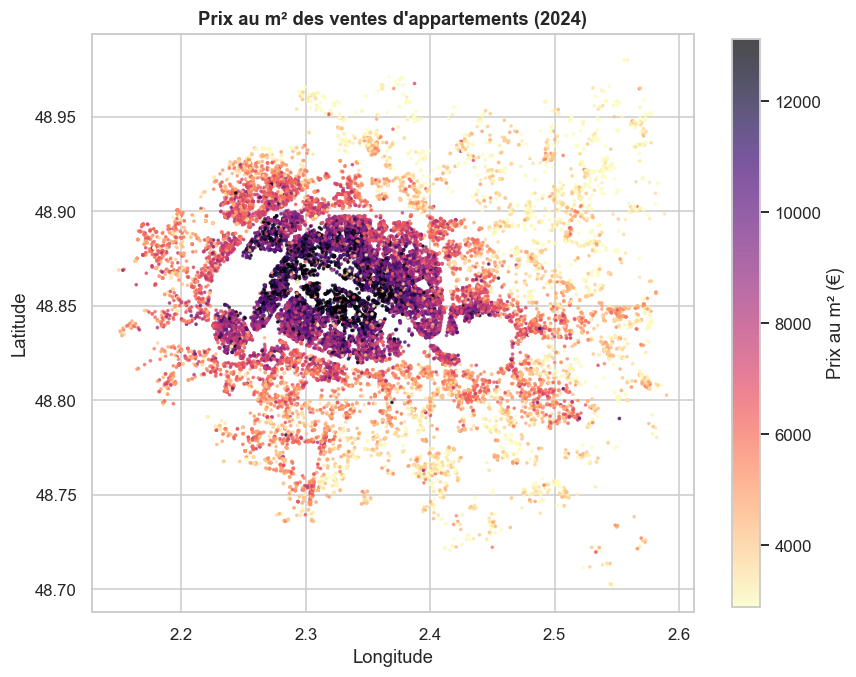

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ech = df.sample(min(len(df), 25000), random_state=RANDOM_STATE)
sc = ax.scatter(ech["longitude"], ech["latitude"], c=ech["prix_m2"], s=2, cmap="magma_r",
                vmin=df["prix_m2"].quantile(.05), vmax=df["prix_m2"].quantile(.95), alpha=.7)
plt.colorbar(sc, ax=ax, label="Prix au m² (€)", shrink=.8)
ax.set(title="Prix au m² des ventes d'appartements (2024)", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1 / np.cos(np.radians(48.86)))
plt.tight_layout(); plt.savefig("../figures/carte_prix.png", bbox_inches="tight"); plt.show()

La carte fait ressortir un **gradient centre-ouest / est** : les prix les plus élevés sont dans le centre et l'ouest parisien et dans les communes limitrophes de l'ouest (Neuilly, Boulogne, Levallois), les plus bas dans le nord-est de la Seine-Saint-Denis.

### 3.4 Surface, nombre de pièces et saisonnalité

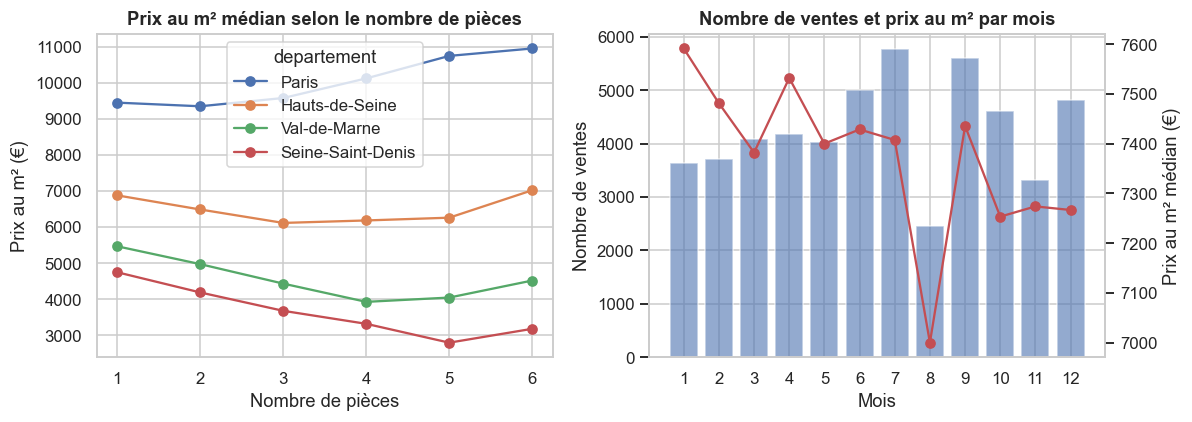

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

pieces = df[df["nombre_pieces_principales"] <= 6].groupby(["nombre_pieces_principales", "departement"])["prix_m2"].median().unstack()
pieces[["Paris", "Hauts-de-Seine", "Val-de-Marne", "Seine-Saint-Denis"]].plot(marker="o", ax=axes[0])
axes[0].set(title="Prix au m² médian selon le nombre de pièces", xlabel="Nombre de pièces", ylabel="Prix au m² (€)")

mensuel = df.groupby("mois").agg(ventes=("prix_m2", "size"), prix_m2=("prix_m2", "median"))
axes[1].bar(mensuel.index, mensuel["ventes"], color=sns.color_palette("deep")[0], alpha=.6)
axes[1].set(title="Nombre de ventes et prix au m² par mois", xlabel="Mois", ylabel="Nombre de ventes")
ax2 = axes[1].twinx()
ax2.plot(mensuel.index, mensuel["prix_m2"], color=sns.color_palette("deep")[3], marker="o")
ax2.set_ylabel("Prix au m² médian (€)"); ax2.grid(False)
axes[1].set_xticks(range(1, 13))

plt.tight_layout(); plt.savefig("../figures/pieces_saisonnalite.png", bbox_inches="tight"); plt.show()

**À retenir :**
- Les **petites surfaces** (studios, 2 pièces) ont le prix au m² le plus élevé : c'est un effet classique, le prix d'une cuisine et d'une salle de bain se répartit sur moins de m².
- Le nombre de ventes varie selon les mois, alors que le prix au m² médian reste relativement stable sur l'année.

## 4. Modélisation : prédire le prix de vente

**Cible :** le prix de vente (`valeur_fonciere`). On prédit son **logarithme**, car les prix sont très asymétriques ; une erreur de 10 % pèse alors autant pour un studio que pour un grand appartement.

**Variables explicatives :** surface, nombre de pièces, commune ou arrondissement, latitude et longitude, mois de la vente.

**Méthode :** 80 % des ventes servent à entraîner les modèles, 20 % à les évaluer sur des données jamais vues. On compare :
1. une **référence naïve** : prix au m² médian de la commune × surface ;
2. une **régression linéaire régularisée (Ridge)** ;
3. une **forêt aléatoire (Random Forest)** ;
4. un **Gradient Boosting** (HistGradientBoosting).

In [8]:
features_num = ["surface_reelle_bati", "nombre_pieces_principales", "latitude", "longitude", "mois"]
features_cat = ["commune"]
X = df[features_num + features_cat]
y = np.log(df["valeur_fonciere"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
prix_test = np.exp(y_test)
print(f"Entraînement : {len(X_train):,} ventes — Test : {len(X_test):,} ventes".replace(",", " "))

def evaluer(nom, pred_prix):
    return {
        "modèle": nom,
        "MAE (€)": mean_absolute_error(prix_test, pred_prix),
        "Erreur médiane (%)": 100 * np.median(np.abs(pred_prix - prix_test) / prix_test),
        "MAPE (%)": 100 * mean_absolute_percentage_error(prix_test, pred_prix),
        "R² (log)": r2_score(y_test, np.log(pred_prix)),
    }

resultats = []

# 1. Référence : prix au m² médian de la commune (calculé sur le jeu d'entraînement) × surface
m2_commune = (np.exp(y_train) / X_train["surface_reelle_bati"]).groupby(X_train["commune"]).median()
pred_ref = X_test["commune"].map(m2_commune).fillna(m2_commune.median()) * X_test["surface_reelle_bati"]
resultats.append(evaluer("Référence (médiane commune × surface)", pred_ref))

preparation = ColumnTransformer([
    ("num", StandardScaler(), features_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
])

modeles = {
    "Régression Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08, random_state=RANDOM_STATE),
}
pipelines = {}
for nom, modele in modeles.items():
    pipe = Pipeline([("prep", preparation), ("modele", modele)])
    if nom == "Gradient Boosting":
        # Le Gradient Boosting gère nativement les catégories : on encode la commune en entier
        X_tr = X_train.assign(commune=X_train["commune"].astype("category").cat.codes)
        cats = X_train["commune"].astype("category").cat.categories
        X_te = X_test.assign(commune=pd.Categorical(X_test["commune"], categories=cats).codes)
        modele.set_params(categorical_features=[len(features_num)])
        modele.fit(X_tr[features_num + features_cat], y_train)
        pred = np.exp(modele.predict(X_te[features_num + features_cat]))
        pipelines[nom] = (modele, X_te[features_num + features_cat])
    else:
        pipe.fit(X_train, y_train)
        pred = np.exp(pipe.predict(X_test))
        pipelines[nom] = (pipe, X_test)
    resultats.append(evaluer(nom, pred))

tableau = pd.DataFrame(resultats).set_index("modèle")
tableau.style.format({"MAE (€)": "{:,.0f}", "Erreur médiane (%)": "{:.1f}", "MAPE (%)": "{:.1f}", "R² (log)": "{:.3f}"})

Entraînement : 40 960 ventes — Test : 10 240 ventes


,MAE (€),Erreur médiane (%),MAPE (%),R² (log)
modèle,,,,
Référence (médiane commune × surface),"72,125",14.2,20.2,0.861
Régression Ridge,"95,436",17.6,24.5,0.807
Random Forest,"68,001",13.0,18.4,0.876
Gradient Boosting,"67,084",12.9,18.1,0.880


### 4.1 Le meilleur modèle : prédictions et erreurs

Meilleur modèle : Gradient Boosting


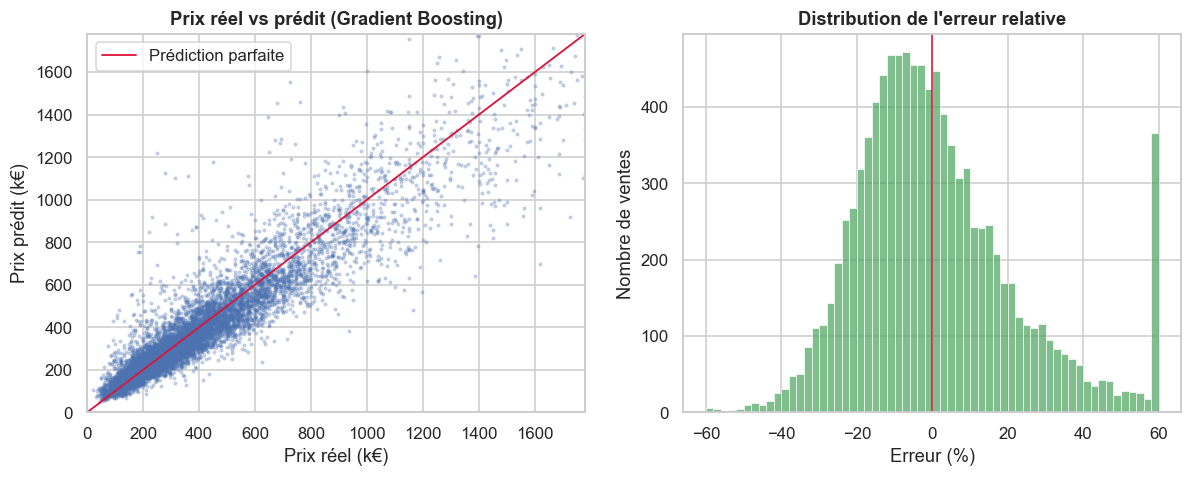

57% des prix prédits sont à moins de 15 % du prix réel.


In [9]:
meilleur = tableau.drop(index="Référence (médiane commune × surface)")["MAE (€)"].idxmin()
modele, X_eval = pipelines[meilleur]
pred = np.exp(modele.predict(X_eval))
print(f"Meilleur modèle : {meilleur}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(prix_test / 1e3, pred / 1e3, s=3, alpha=.25)
lim = np.percentile(prix_test / 1e3, 99)
axes[0].plot([0, lim], [0, lim], color="crimson", lw=1.2, label="Prédiction parfaite")
axes[0].set(xlim=(0, lim), ylim=(0, lim), title=f"Prix réel vs prédit ({meilleur})", xlabel="Prix réel (k€)", ylabel="Prix prédit (k€)")
axes[0].legend()

erreur_pct = 100 * (pred - prix_test) / prix_test
sns.histplot(erreur_pct.clip(-60, 60), bins=60, ax=axes[1], color=sns.color_palette("deep")[2])
axes[1].axvline(0, color="crimson", lw=1)
axes[1].set(title="Distribution de l'erreur relative", xlabel="Erreur (%)", ylabel="Nombre de ventes")

plt.tight_layout(); plt.savefig("../figures/predictions.png", bbox_inches="tight"); plt.show()
print(f"{(erreur_pct.abs() <= 15).mean():.0%} des prix prédits sont à moins de 15 % du prix réel.")

### 4.2 Quelles variables comptent le plus ?

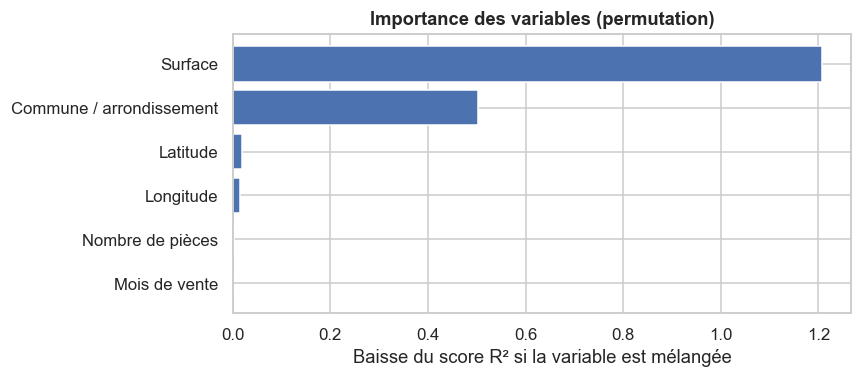

In [10]:
imp = permutation_importance(modele, X_eval, np.log(prix_test), n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=X_eval.columns).sort_values()
noms = {"surface_reelle_bati": "Surface", "nombre_pieces_principales": "Nombre de pièces", "latitude": "Latitude",
        "longitude": "Longitude", "mois": "Mois de vente", "commune": "Commune / arrondissement"}
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([noms[c] for c in importances.index], importances.values, color=sns.color_palette("deep")[0])
ax.set(title="Importance des variables (permutation)", xlabel="Baisse du score R² si la variable est mélangée")
plt.tight_layout(); plt.savefig("../figures/importance_variables.png", bbox_inches="tight"); plt.show()

In [11]:
# Résumé exporté pour le README
resume_json = {
    "ventes_analysees": int(len(df)),
    "prix_m2_median": {k: int(v) for k, v in resume["prix_m2_median"].items()},
    "arrondissement_plus_cher": [arr.index[-1], int(arr.iloc[-1])],
    "arrondissement_moins_cher": [arr.index[0], int(arr.iloc[0])],
    "modeles": {k: {m: round(float(v), 3) for m, v in row.items()} for k, row in tableau.iterrows()},
    "meilleur_modele": meilleur,
    "part_a_moins_de_15pct": round(float((erreur_pct.abs() <= 15).mean()), 3),
}
with open("../figures/resultats.json", "w", encoding="utf-8") as f:
    json.dump(resume_json, f, ensure_ascii=False, indent=2)
resume_json

{'ventes_analysees': 51200,
 'prix_m2_median': {'Paris': 9553,
  'Hauts-de-Seine': 6395,
  'Val-de-Marne': 4696,
  'Seine-Saint-Denis': 4000},
 'arrondissement_plus_cher': ['6e', 13603],
 'arrondissement_moins_cher': ['19e', 7822],
 'modeles': {'Référence (médiane commune × surface)': {'MAE (€)': 72124.512,
   'Erreur médiane (%)': 14.204,
   'MAPE (%)': 20.152,
   'R² (log)': 0.861},
  'Régression Ridge': {'MAE (€)': 95436.245,
   'Erreur médiane (%)': 17.649,
   'MAPE (%)': 24.546,
   'R² (log)': 0.807},
  'Random Forest': {'MAE (€)': 68001.017,
   'Erreur médiane (%)': 13.01,
   'MAPE (%)': 18.414,
   'R² (log)': 0.876},
  'Gradient Boosting': {'MAE (€)': 67083.8,
   'Erreur médiane (%)': 12.916,
   'MAPE (%)': 18.126,
   'R² (log)': 0.88}},
 'meilleur_modele': 'Gradient Boosting',
 'part_a_moins_de_15pct': 0.57}

## 5. Conclusions et limites

**Ce que montrent les données**
- Pour le **prix total**, la **surface** est le premier facteur, suivie de la **localisation** (commune ou arrondissement). Pour le **prix au m²**, c'est la localisation qui fait tout : il va du simple au triple entre la Seine-Saint-Denis et le centre de Paris.
- Le nombre de pièces et le mois de vente n'apportent presque rien une fois la surface et la commune connues.
- Les petites surfaces sont plus chères au m².
- Les modèles à base d'arbres (Random Forest, Gradient Boosting) font **mieux que la règle simple** « prix médian de la commune × surface », car ils captent des effets plus fins (position exacte, interaction surface × quartier). **Mais le gain reste modeste** : l'essentiel du prix s'explique déjà par la localisation et la surface.
- La régression linéaire fait moins bien que la référence : la relation entre prix, surface et position n'est pas linéaire.
- Conclusion honnête : avec seulement ces variables, on estime un prix à environ ±13 % (erreur médiane). Pour faire mieux, il faut **plus d'informations sur le bien**, pas un modèle plus complexe.

**Limites**
- DVF ne contient pas l'**état du bien**, l'étage, la présence d'un ascenseur, d'un balcon, le DPE… Une part importante de l'écart restant vient de ces informations absentes.
- Une seule année (2024) : le modèle ne capte pas l'évolution des prix dans le temps.
- Les ventes en lot (appartement + autre local) ont été écartées pour garder des prix au m² fiables.

**Pistes**
- Ajouter des données externes : distance au métro (open data RATP/IDFM), revenus médians par IRIS (INSEE), DPE (ADEME).
- Étendre à plusieurs années pour mesurer l'évolution des prix.
- Déployer le modèle dans une petite application d'estimation.